# Decision Tree

A single decision tree: a flowchart of yes/no questions on feature thresholds (e.g. "is `same_srv_rate` ≤ 0.3?"), learned by picking at each step the split that best separates normal from DoS rows (Gini impurity). Thresholds don't care about scale, so no scaling is needed.

It is the building block of Random Forest (notebook 04). Defined in `src/dosdetect/models.py` as `decision_tree()`; grown to full depth by default.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only (`dosdetect.data.prepare_all`). Four setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **8 features** (the paper's top 8 by |correlation| with the label) or **all 41**.

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["decision_tree"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8531,0.9802,0.6755,0.7998,0.8150,0.2091,0.0788,0.0014
"official, 41 features",0.9054,0.9784,0.7999,0.8802,0.9873,0.1736,0.4587,0.0016
"holdout, 8 features",0.9602,0.9850,0.9158,0.9492,NaN,NaN,0.0594,0.0017
"holdout, 41 features",0.9997,0.9996,0.9997,0.9996,NaN,NaN,0.3297,0.0024


### Confusion matrices

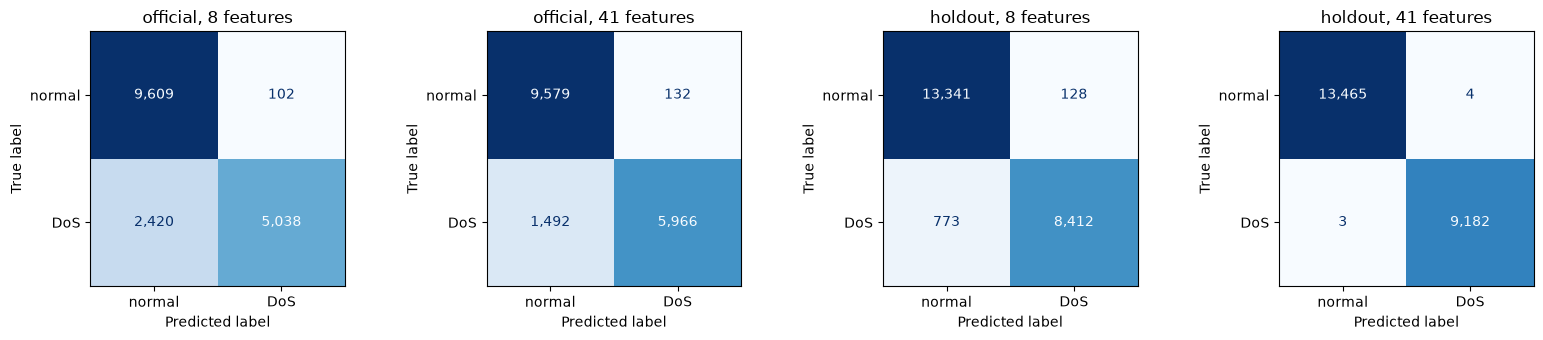

In [4]:
plot_confusions(results);

## Tree depth

A full-depth tree can memorise the training data. Limiting depth makes it simpler. 8 features.

,official,holdout
max_depth,,
2,0.8330,0.9547
4,0.8333,0.9561
6,0.8533,0.9552
8,0.8551,0.9576
10,0.8546,0.9590
15,0.8538,0.9609
20,0.8537,0.9618
None,0.8531,0.9602


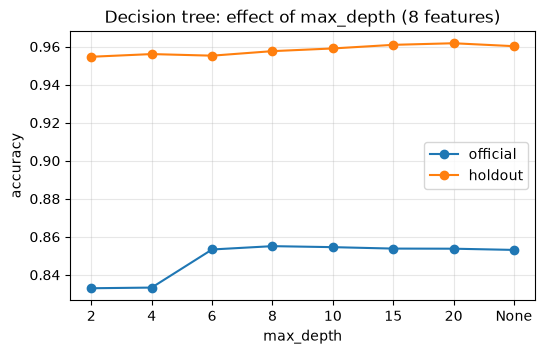

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

depths = [2, 4, 6, 8, 10, 15, 20, None]
depth_table = pd.DataFrame(
    {
        split: [
            evaluate(DecisionTreeClassifier(max_depth=d, random_state=42), data[(split, 8)])[
                "accuracy"
            ]
            for d in depths
        ]
        for split in ("official", "holdout")
    },
    index=pd.Index([str(d) for d in depths], name="max_depth"),
)
ax = depth_table.plot(marker="o", figsize=(6, 3.5))
ax.set(ylabel="accuracy", title="Decision tree: effect of max_depth (8 features)")
ax.grid(alpha=0.3)
depth_table

## What the tree learned

The top three levels of the full tree (official training data, 8 features), and how much each feature contributes.

Depth: 39  Leaves: 1728


,importance
same_srv_rate,0.8309
flag,0.0718
dst_host_serror_rate,0.0395
dst_host_srv_count,0.0278
dst_host_same_srv_rate,0.0176
serror_rate,0.0063
dst_host_srv_serror_rate,0.0059
srv_serror_rate,0.0003


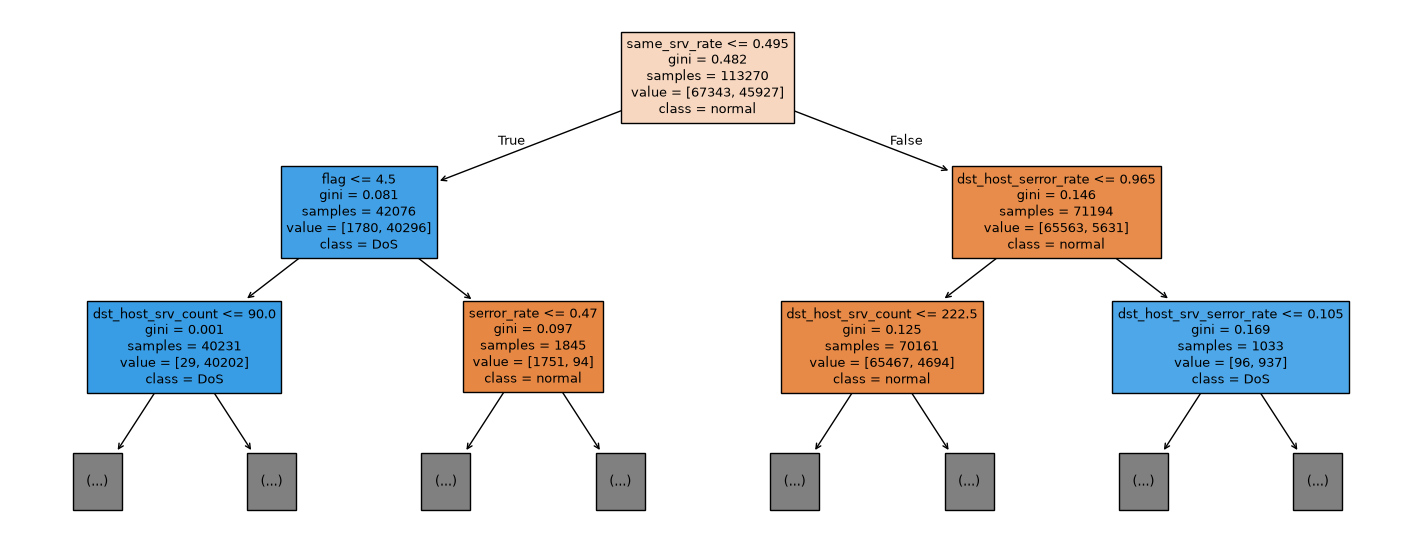

In [6]:
tree = MODELS["decision_tree"]().fit(official["X_train"], official["y_train"])
print("Depth:", tree.get_depth(), " Leaves:", tree.get_n_leaves())
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    tree,
    max_depth=2,
    feature_names=list(official["X_train"].columns),
    class_names=["normal", "DoS"],
    filled=True,
    fontsize=9,
    ax=ax,
)
pd.Series(tree.feature_importances_, official["X_train"].columns, name="importance").sort_values(
    ascending=False
).to_frame()

## Takeaways

- **As accurate as the Random Forest from a single tree.** 96.0% on the holdout split (8 features), 90.5% on the official file with 41 features, within 0.3 points of Random Forest in both setups. It trains in under 0.5 s, about 10x faster than the forest.
- **Unseen attacks are still the weak spot**: 17–21% recall on never-seen DoS types. The tree learns thresholds that fit known attacks and has no reason to flag traffic outside them.
- **Depth barely matters past 6.** Official accuracy stays between 85.3% and 85.5% from depth 6 to full depth. A depth-6 tree is far easier to read and explain in a forensics report.
- **One feature does most of the work.** `same_srv_rate` (share of recent connections to the same service) accounts for most of the tree's importance, followed by `flag`. DoS floods hammer one service, so this is an easy feature to justify to an investigator.